In [1]:
import pandas as pd
import anndata as ad
import numpy as np

In [13]:
# sc_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/label_transfer/SC_NSCLC_labeltransfer.h5ad')
st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/processed_adata/ST_NSCLC_labeltransfer_consolidated_withprobs.h5ad')
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/processed_adata/SC_NSCLC_labeltransfer_admixed_10reps.h5ad')
sc_data = sc_data[sc_data.obs.index.str.endswith("_0")]
sc_data.obs['cell_type'] = sc_data.obs['cell_type'].replace({"T CD4 naive": "T CD4+", 
                                                                "T CD4 memory": "T CD4+", 
                                                                "T CD8 naive": "T CD8+", 
                                                                "T CD8 memory": "T CD8+",
                                                                "pDC":"DC",
                                                                "mDC":"DC"})
l5r1_metadata = pd.read_csv('/compute/oven-0-13/jwinchel/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')

st_data = st_data[st_data.obs['Run_Tissue_name']=='Lung5_Rep1']
# st_data.obs = st_data.obs.merge(l5r1_metadata[['fov','cell_ID','CenterX_local_px',
#        'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px']],on=['fov','cell_ID'])

st_data.obs['cell_type'] = st_data.obs['cell_type'].astype(str)
st_data.obs.loc[st_data.obs['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'

sc_data.obs['cell_type'] = sc_data.obs['cell_type'].astype(str)
sc_data.obs.loc[sc_data.obs['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'

st_data.obs['cell_type'].value_counts()

/tmp/ipykernel_3629126/2972248045.py:5: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  sc_data.obs['cell_type'] = sc_data.obs['cell_type'].replace({"T CD4 naive": "T CD4+",
/tmp/ipykernel_3629126/2972248045.py:17: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  st_data.obs['cell_type'] = st_data.obs['cell_type'].astype(str)


cell_type
tumor          18600
fibroblast     13151
neutrophil      9925
T CD4+          7692
endothelial     7613
macrophage      7409
B-cell          7207
DC              7088
plasmablast     7079
epithelial      4098
mast            2462
T CD8+          2020
monocyte        1843
NK              1668
Treg             147
Name: count, dtype: int64

In [14]:
from scipy import sparse
import numpy as np
def gene_cell_admix_df(
    adata,
    probs_layer="admix_probs",
    thr=0.5,
    use_nonzero_only=True,
):
    """
    Returns a long dataframe with columns:
      cell, gene, prob, is_admixed, status
    If use_nonzero_only=True, restrict to entries where X > 0 (i.e., observed transcripts).
    """
    probs = adata.layers[probs_layer]
    if sparse.issparse(probs):
        probs = probs.toarray()

    X = adata.X
    if sparse.issparse(X):
        X = X.tocsr()

    cells = np.asarray(adata.obs_names)
    genes = np.asarray(adata.var_names)

    if use_nonzero_only:
        if not sparse.issparse(adata.X):
            nz = np.nonzero(X)
            r, c = nz
        else:
            r, c = X.nonzero()

        df = pd.DataFrame({
            "cell": adata.obs['cell_ID'].values[r],
            "fov": adata.obs['fov'].values[r],
            "gene": genes[c],
            "prob": probs[r, c],
            "cell_type": adata.obs['cell_type'].values[r],
        })
    else:
        # WARNING: can be huge (n_cells * n_genes)
        r, c = np.indices(probs.shape)
        df = pd.DataFrame({
            "cell": cells[r.ravel()],
            "gene": genes[c.ravel()],
            "prob": probs.ravel(),
        })

    df["is_admixed"] = df["prob"] > thr
    df["status"] = np.where(df["is_admixed"], "admixed", "kept")
    return df

gene_cell_df = gene_cell_admix_df(st_data, probs_layer="admix_probs", thr=0.674, use_nonzero_only=True)

In [5]:
gene_cell_df

,cell,fov,gene,prob,cell_type,is_admixed,status
0,1.0,1.0,ENSG00000019582,0.000000,DC,False,kept
1,1.0,1.0,ENSG00000060138,0.000000,DC,False,kept
2,1.0,1.0,ENSG00000069493,0.000000,DC,False,kept
3,1.0,1.0,ENSG00000090104,0.752824,DC,True,admixed
4,1.0,1.0,ENSG00000107738,0.734360,DC,True,admixed
...,...,...,...,...,...,...,...
12607108,4755.0,30.0,ENSG00000173272,0.726899,fibroblast,True,admixed
12607109,4755.0,30.0,ENSG00000187955,0.678569,fibroblast,True,admixed
12607110,4755.0,30.0,ENSG00000204592,0.756662,fibroblast,True,admixed
12607111,4755.0,30.0,ENSG00000211445,0.713008,fibroblast,True,admixed


In [6]:
st_data.obs

,fov,cell_ID,tissue,sdimx,sdimy,Area,AspectRatio,Width,Height,Mean.CD298,...,cell_type,niche,prop_tumor_in_100_neighbors,cell_ID_short,batch,CenterX_local_px,CenterY_local_px,CenterX_global_px,CenterY_global_px,split
0,1.0,1.0,Lung5_Rep1,28.78886,-3.28806,1259.0,1.34,47.0,35.0,3473.0,...,DC,plasmablast-enriched stroma,0.09,1.0,st,1027,3631,4215.888889,158847.666667,val
1,1.0,2.0,Lung5_Rep1,29.12672,-3.29040,3723.0,1.45,87.0,60.0,3895.0,...,endothelial,stroma,0.00,2.0,st,2904,3618,6092.888889,158834.666667,train
2,1.0,3.0,Lung5_Rep1,29.32868,-3.28878,2010.0,1.62,68.0,42.0,2892.0,...,endothelial,stroma,0.01,3.0,st,4026,3627,7214.888889,158843.666667,val
3,1.0,4.0,Lung5_Rep1,29.36540,-3.29418,3358.0,0.47,48.0,102.0,6189.0,...,DC,stroma,0.00,4.0,st,4230,3597,7418.888889,158813.666667,val
4,1.0,5.0,Lung5_Rep1,29.37044,-3.28842,1213.0,1.00,38.0,38.0,8138.0,...,macrophage,stroma,0.00,5.0,st,4258,3629,7446.888889,158845.666667,val
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97997,30.0,4750.0,Lung5_Rep1,32.87952,-0.65358,1614.0,2.06,64.0,31.0,889.0,...,DC,stroma,0.00,4750.0,st,1864,17,26941.777778,173483.666667,val
97998,30.0,4751.0,Lung5_Rep1,32.89248,-0.65430,1346.0,2.83,68.0,24.0,577.0,...,fibroblast,stroma,0.00,4751.0,st,1936,13,27013.777778,173479.666667,val
97999,30.0,4752.0,Lung5_Rep1,33.39126,-0.65376,1336.0,1.86,54.0,29.0,309.0,...,DC,lymphoid structure,0.00,4752.0,st,4707,16,29784.777778,173482.666667,val
98000,30.0,4753.0,Lung5_Rep1,33.44832,-0.65466,803.0,2.58,49.0,19.0,834.0,...,B-cell,lymphoid structure,0.00,4753.0,st,5024,11,30101.777778,173477.666667,val


In [15]:
gene_cell_df = st_data.obs[['fov','cell_ID','slide_ID_numeric', 'Run_Tissue_name', 'Panel', 'Diversity',
       'totalcounts', 'log10totalcounts', 'background', 'remove_flagged_cells',
       'patient','niche', 'prop_tumor_in_100_neighbors',
       'cell_ID_short', 'batch', 'CenterX_local_px', 'CenterY_local_px',
       'CenterX_global_px', 'CenterY_global_px']].merge(gene_cell_df,left_on=['fov','cell_ID'],right_on=['fov','cell'],how='right')

In [39]:
admixed_mask = (st_data.layers['admix_probs'] > 0.674).sum(axis=1) > 0
admixed_mask.shape

(98002,)

In [32]:
st_admixed = st_data[admixed_mask]

In [45]:
st_data.obs['is_admixed'] = admixed_mask

In [40]:
st_data.obs['mean_admix_prob'] = st_data.layers['admix_probs'].mean(axis=1)

In [34]:
st_admixed.obs

,fov,cell_ID,tissue,sdimx,sdimy,Area,AspectRatio,Width,Height,Mean.CD298,...,niche,prop_tumor_in_100_neighbors,cell_ID_short,batch,CenterX_local_px,CenterY_local_px,CenterX_global_px,CenterY_global_px,split,mean_admix_prob
0,1.0,1.0,Lung5_Rep1,28.78886,-3.28806,1259.0,1.34,47.0,35.0,3473.0,...,plasmablast-enriched stroma,0.09,1.0,st,1027,3631,4215.888889,158847.666667,val,0.011927
2,1.0,3.0,Lung5_Rep1,29.32868,-3.28878,2010.0,1.62,68.0,42.0,2892.0,...,stroma,0.01,3.0,st,4026,3627,7214.888889,158843.666667,val,0.035196
3,1.0,4.0,Lung5_Rep1,29.36540,-3.29418,3358.0,0.47,48.0,102.0,6189.0,...,stroma,0.00,4.0,st,4230,3597,7418.888889,158813.666667,val,0.033297
4,1.0,5.0,Lung5_Rep1,29.37044,-3.28842,1213.0,1.00,38.0,38.0,8138.0,...,stroma,0.00,5.0,st,4258,3629,7446.888889,158845.666667,val,0.024169
6,1.0,8.0,Lung5_Rep1,28.74872,-3.29076,4376.0,1.38,88.0,64.0,2275.0,...,plasmablast-enriched stroma,0.04,8.0,st,804,3616,3992.888889,158832.666667,val,0.029011
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97997,30.0,4750.0,Lung5_Rep1,32.87952,-0.65358,1614.0,2.06,64.0,31.0,889.0,...,stroma,0.00,4750.0,st,1864,17,26941.777778,173483.666667,val,0.020549
97998,30.0,4751.0,Lung5_Rep1,32.89248,-0.65430,1346.0,2.83,68.0,24.0,577.0,...,stroma,0.00,4751.0,st,1936,13,27013.777778,173479.666667,val,0.035165
97999,30.0,4752.0,Lung5_Rep1,33.39126,-0.65376,1336.0,1.86,54.0,29.0,309.0,...,lymphoid structure,0.00,4752.0,st,4707,16,29784.777778,173482.666667,val,0.030719
98000,30.0,4753.0,Lung5_Rep1,33.44832,-0.65466,803.0,2.58,49.0,19.0,834.0,...,lymphoid structure,0.00,4753.0,st,5024,11,30101.777778,173477.666667,val,0.008182


In [19]:
gene_ct_df = gene_cell_df.groupby(['gene','cell_type'])['prob'].mean().reset_index(name='mean_prob')

<Axes: xlabel='cell_type', ylabel='cell_type'>

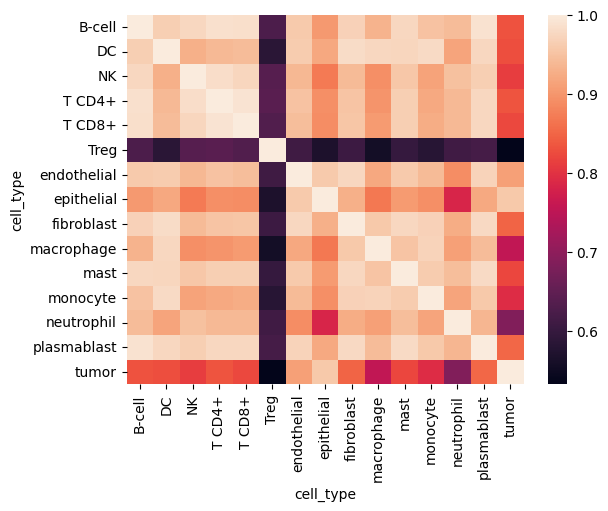

In [29]:
import seaborn as sns
sns.heatmap(gene_ct_df.pivot(index='gene', columns='cell_type', values='mean_prob').fillna(0).corr(method='pearson'))

In [23]:
# for ct in gene_ct_df['cell_type'].unique():
#     print(f"Cell type: {ct}")
#     display(gene_ct_df[gene_ct_df['cell_type'] == ct].sort_values('mean_prob', ascending=False).head(10).gene.tolist())

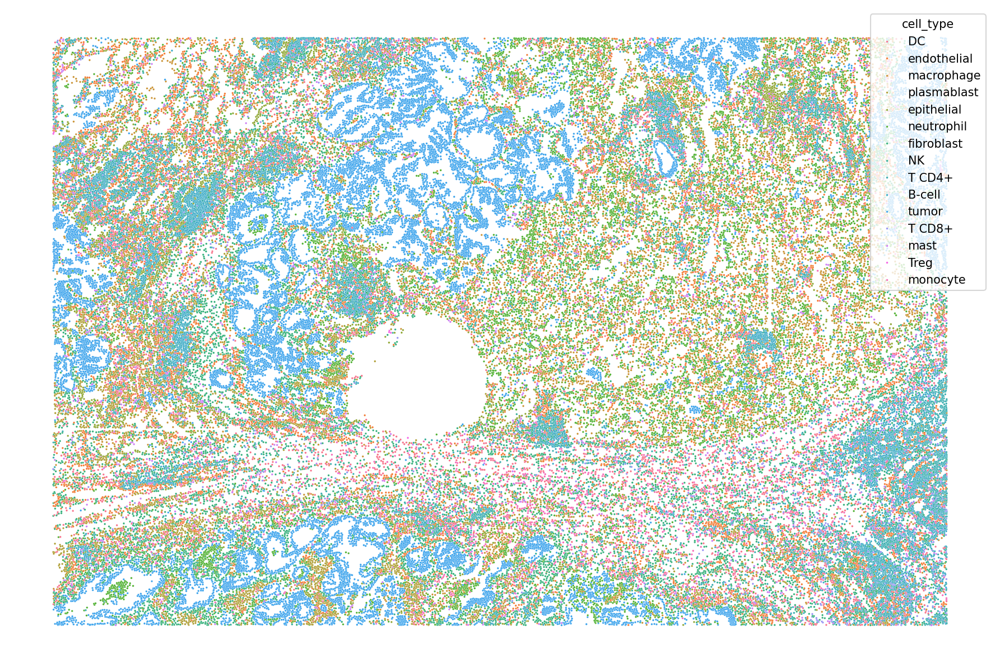

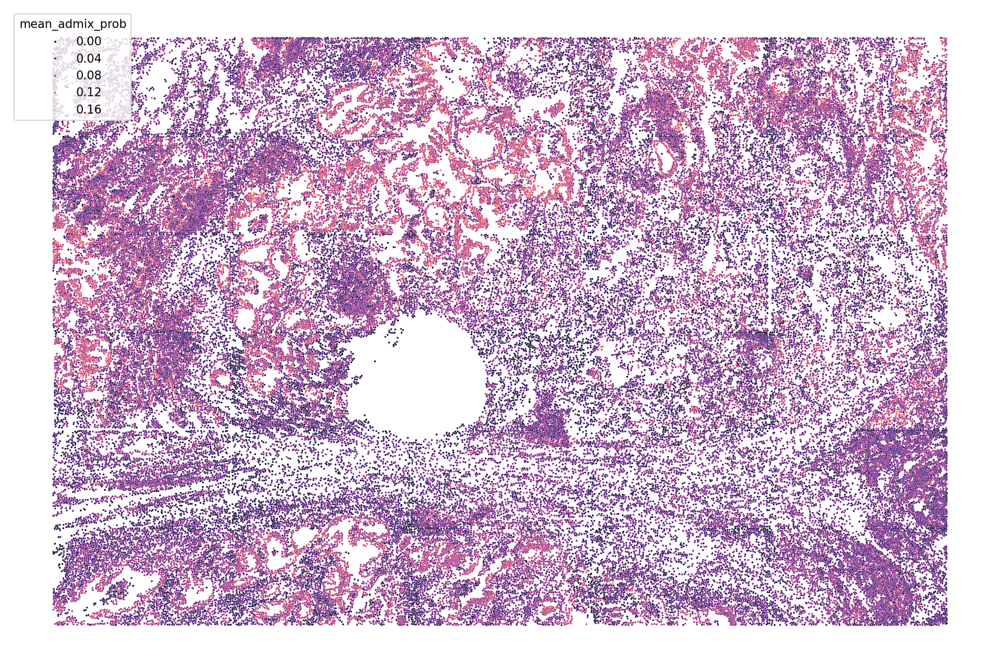

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

FOV = 15
fig,ax = plt.subplots(figsize=(12,8),dpi=150)
sns.scatterplot(x='CenterX_global_px', y='CenterY_global_px', hue='cell_type', data=st_data.obs,ax=ax,s=3)
ax.invert_yaxis()
_ = ax.axis('off')
fig.tight_layout()
fig.show()

fig,ax = plt.subplots(figsize=(12,8),dpi=150)
sns.scatterplot(x='CenterX_global_px', y='CenterY_global_px', hue='mean_admix_prob', data=st_data.obs,ax=ax,s=3,palette='magma')
ax.invert_yaxis()
_ = ax.axis('off')
fig.tight_layout()
fig.show()

<Axes: xlabel='mean_admix_prob', ylabel='niche'>

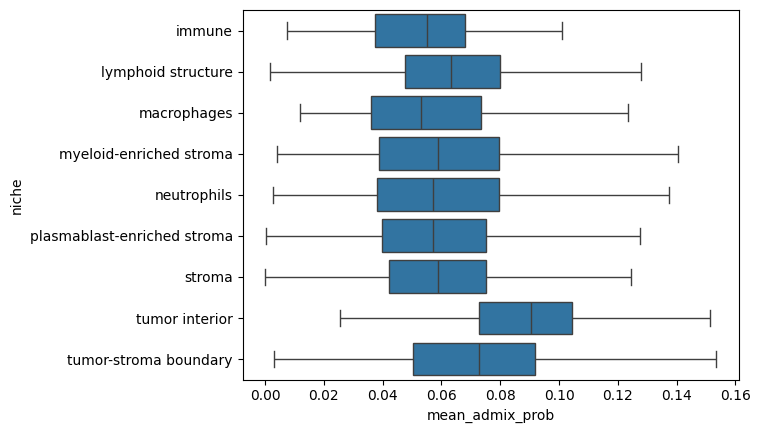

In [ ]:
sns.boxplot(data=st_data.obs,y='niche',x='mean_admix_prob',showfliers = False)